# 02 · `gmsEDA` decomposition **without per-subject normalisation**

**Question.** Does decomposing each 1-min E4 EDA window with `eda_proj.gms_eda.gmsEDA` improve
baseline-vs-stress classification when **no per-subject normalisation** is used? Here every feature is computed
on the window in µS. This is the harder setting, because skin-conductance levels differ more than 10× between people.

**Setup.** Windows come from notebook 01: 60 s windows with a 10 s stride and 100 % label purity.
Evaluation is leave-one-subject-out (LOSO) over the 15 subjects.

* `raw`: the 33 signal features of `raw_features`, in µS.
* `raw+rel`: `raw` plus 14 scale-free ratios (spread / slope / derivative / peak features divided by the window
  mean). This is a control, because the decomposition features also contain a few such ratios.
* `gms`: 28 features of the `gmsEDA` output, with tonic, phasic, positive and negative driver parts, and 6 scale-free
  ratios (`eda_utils.gms_signed_features`).
* `med`: the same 28 features computed from a naive running-median decomposition. This is the control for
  "any tonic/phasic split".

**`gmsEDA` parameters explored.** `src/eda_proj/gms_eda.py` now accepts `lam_scale` (λ = lam_scale/√max(N,K);
default 3 as before):

| parameter | values |
|---|---|
| `num_of_chops` | 2, 3, 5, 10, 20, 30, 40, 60 |
| `overlap` | 0, 0.5, 0.8, 0.9, 0.95 |
| `lam_scale` | 0.3, 0.5, 1, 2, 3, 10 |
| `force_nn` | 0 (new default), 1 |

There are 112 configurations. The full grid is 5 chops × 4 overlaps × 5 λ, plus a refinement around the best region.
Decomposing 2,599 windows takes 10–240 s per configuration, so only the resulting feature tables are cached
(`cache/gms_grid_features_part*.npz`).

**Avoiding selection bias.** Picking the best of 112 configurations on the same LOSO results is optimistic.
Section 4 therefore runs a **nested LOSO**: for each held-out subject, the configuration is chosen by an inner
5-fold group CV on the other 14 subjects only. "No decomposition" is also one of the candidates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time, itertools
warnings.filterwarnings("ignore")
from eda_utils import *
from eda_proj.gms_eda import gmsEDA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

STRIDE = 10
W = np.load(CACHE / f"windows_stride{STRIDE}.npz")["W"]          # raw µS windows
meta = pd.read_csv(CACHE / f"windows_meta_stride{STRIDE}.csv")
y, groups = meta.label.values, meta.subject.values
print(W.shape)

(2599, 240)


## 1. Baseline features (µS, no normalisation) and the running-median control

In [2]:
f_raw = CACHE / "rawfeat_abs.csv"
if not f_raw.exists():
    pd.DataFrame([raw_features_abs(w) for w in W]).replace([np.inf, -np.inf], np.nan).fillna(0).to_csv(f_raw, index=False)
R = pd.read_csv(f_raw)
RAW = R[[c for c in R if not c.startswith("rel_")]]
RAWREL = R

f_med = CACHE / "medfeat_abs.csv"
if not f_med.exists():
    rows = []
    for w in W:
        ton, ph = smooth_decompose_window(w)
        rows.append(gms_signed_features(w, np.zeros_like(w), ton, ph, prefix="med"))
    pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).fillna(0).to_csv(f_med, index=False)
MED = pd.read_csv(f_med)
print(RAW.shape, RAWREL.shape, MED.shape)

(2599, 33) (2599, 47) (2599, 28)


## 2. Grid over `num_of_chops` × `overlap` × `lam_scale`
Screening with two classifiers: logistic regression and gradient boosting.

In [3]:
# sanity check: the new lam_scale argument with its default reproduces the previous gmsEDA
X_def, _ = gmsEDA(W[500].reshape(-1, 1), FS, 5, 0.8)
X_l3, _ = gmsEDA(W[500].reshape(-1, 1), FS, 5, 0.8, lam_scale=3)
print("lam_scale=3 equals default:", np.allclose(X_def, X_l3))

GRID = grid_tags()
print(len(GRID), "configurations in cache")
# (to recompute a configuration:  gms_config_features(W, dict(num_of_chops=20, overlap=0.9, lam_scale=1, force_nn=0)) )
GF = {r.tag: gms_config_features(W, dict(num_of_chops=int(r.num_of_chops), overlap=float(r.overlap),
                                          lam_scale=float(r.lam_scale), force_nn=int(r.force_nn)))
      for r in GRID.itertuples()}

lam_scale=3 equals default: True
112 configurations in cache


In [4]:
SCREEN_MODELS = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "HistGB": lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_depth=3, random_state=0),
}
f_scr = CACHE / "gms_grid_screen.csv"
scr = pd.read_csv(f_scr) if f_scr.exists() else pd.DataFrame(columns=["tag", "features", "model", "acc", "f1"])
todo = [t for t in GF if t not in set(scr.tag)]
t0 = time.time()
rows = []
for t in ["none"] + todo if "none" not in set(scr.tag) else todo:
    for fs, X in ([("raw", RAW)] if t == "none" else [("gms", GF[t]), ("raw+gms", pd.concat([RAW, GF[t]], axis=1))]):
        for m, fn in SCREEN_MODELS.items():
            s, _ = loso_eval(fn, X.values, y, groups)
            rows.append(dict(tag=t, features=fs, model=m, acc=s["acc"], f1=s["f1"]))
if rows:
    scr = pd.concat([scr, pd.DataFrame(rows)], ignore_index=True); scr.to_csv(f_scr, index=False)
print(f"{time.time() - t0:.0f}s")
base_acc = scr[scr.tag == "none"].set_index("model").acc
print("raw (no decomposition):", base_acc.round(3).to_dict(), " mean", round(base_acc.mean(), 3))

S = scr[scr.tag != "none"].pivot_table(index="tag", columns=["features", "model"], values="acc")
S.columns = [f"{a} | {b}" for a, b in S.columns]
S["mean raw+gms"] = S[["raw+gms | LogReg", "raw+gms | HistGB"]].mean(axis=1)
S["mean gms"] = S[["gms | LogReg", "gms | HistGB"]].mean(axis=1)
S = GRID.set_index("tag").join(S)
S.sort_values("mean raw+gms", ascending=False).head(15).round(3)

0s
raw (no decomposition): {'LogReg': 0.831, 'HistGB': 0.84}  mean 0.836


,num_of_chops,overlap,lam_scale,force_nn,gms | HistGB,gms | LogReg,raw+gms | HistGB,raw+gms | LogReg,mean raw+gms,mean gms
tag,,,,,,,,,,
c40_o0.8_l1_nn0,40,0.80,1.0,0,0.868,0.863,0.871,0.867,0.869,0.865
c20_o0.9_l1_nn0,20,0.90,1.0,0,0.859,0.864,0.870,0.869,0.869,0.861
c30_o0.8_l1_nn0,30,0.80,1.0,0,0.854,0.863,0.869,0.870,0.869,0.859
c20_o0.95_l1_nn0,20,0.95,1.0,0,0.879,0.850,0.870,0.862,0.866,0.865
c20_o0.8_l1_nn0,20,0.80,1.0,0,0.850,0.854,0.856,0.869,0.863,0.852
c30_o0.9_l1_nn0,30,0.90,1.0,0,0.855,0.843,0.868,0.855,0.861,0.849
c20_o0.9_l1_nn1,20,0.90,1.0,1,0.840,0.850,0.863,0.860,0.861,0.845
c10_o0.9_l1_nn0,10,0.90,1.0,0,0.844,0.850,0.853,0.869,0.861,0.847
c60_o0.8_l1_nn0,60,0.80,1.0,0,0.858,0.853,0.860,0.863,0.861,0.855


### How accuracy depends on the three parameters (full 5 × 4 × 5 grid, `force_nn=0`)
Each cell is the mean LOSO accuracy of LogReg and HistGB for `raw + gms`. The colour scale is centred on the
no-decomposition baseline, so red means better than `raw` alone and blue means worse.

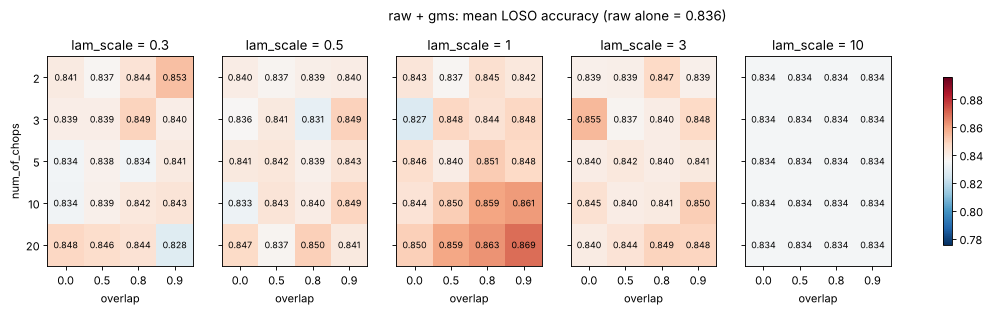

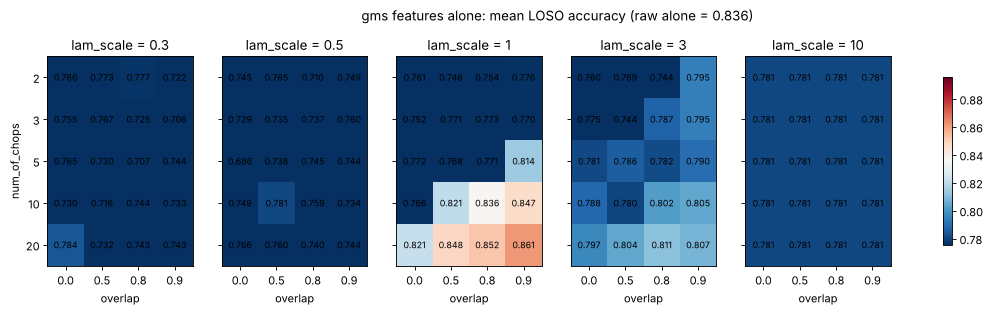

In [5]:
full = S[(S.num_of_chops.isin([2, 3, 5, 10, 20])) & (S.overlap.isin([0, .5, .8, .9])) & (S.force_nn == 0)]
lams = [0.3, 0.5, 1, 3, 10]
b = base_acc.mean()
for col, title in [("mean raw+gms", "raw + gms"), ("mean gms", "gms features alone")]:
    fig, axes = plt.subplots(1, len(lams), figsize=(17, 3.4), sharey=True)
    for ax, lam in zip(axes, lams):
        M = full[full.lam_scale == lam].pivot(index="num_of_chops", columns="overlap", values=col)
        im = ax.imshow(M.values, cmap="RdBu_r", vmin=b - 0.06, vmax=b + 0.06, aspect="auto")
        for (i, j), v in np.ndenumerate(M.values):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8)
        ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns)
        ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
        ax.set_title(f"lam_scale = {lam}"); ax.set_xlabel("overlap")
    axes[0].set_ylabel("num_of_chops")
    fig.suptitle(f"{title}: mean LOSO accuracy (raw alone = {b:.3f})", y=1.06); fig.colorbar(im, ax=axes, shrink=.8)
    plt.show()

Clear pattern:
* **`lam_scale ≈ 1`** is best for every chop/overlap setting. The old default 3 and larger values make the driver
  too sparse, while 0.3–0.5 make it too dense.
* **More chops** (shorter segments: 20 chops → 12 samples = 3 s) and **more overlap** (0.8–0.9) help.
  The gain levels off around 20–40 chops with 0.8–0.9 overlap (see the refinement table above).
* `force_nn=1` (clipping the driver to ≥ 0) is slightly worse than keeping the signed driver.

## 3. Best region — all four classifiers, paired per-subject tests
We pick **`num_of_chops=20, overlap=0.9, lam_scale=1`**, a point in the middle of the plateau. It is compared with
`raw`, `raw+rel` and the median control. Note that this choice was made on the same LOSO results; the unbiased estimate is in section 4.

In [6]:
BEST = "c20_o0.9_l1_nn0"
DEFAULT = "c5_o0.8_l3_nn0"
SETS = {
    "raw": RAW,
    "raw+rel": RAWREL,
    "raw+med": pd.concat([RAW, MED], axis=1),
    f"gms [{DEFAULT}] (old defaults)": GF[DEFAULT],
    f"raw+gms [{DEFAULT}]": pd.concat([RAW, GF[DEFAULT]], axis=1),
    f"gms [{BEST}]": GF[BEST],
    f"raw+gms [{BEST}]": pd.concat([RAW, GF[BEST]], axis=1),
    f"raw+rel+gms [{BEST}]": pd.concat([RAWREL, GF[BEST]], axis=1),
}
t0 = time.time()
res, ptab = compare_feature_sets(SETS, y, groups)
print(f"{time.time() - t0:.0f}s")
acc = res.pivot(index="features", columns="model", values="acc").loc[list(SETS)]
acc["mean"] = acc.mean(axis=1)
acc.round(3)

231s


model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.840,0.831,0.824,0.853,0.837
raw+rel,0.821,0.841,0.831,0.850,0.836
raw+med,0.830,0.828,0.842,0.864,0.841
gms [c5_o0.8_l3_nn0] (old defaults),0.799,0.765,0.797,0.800,0.790
raw+gms [c5_o0.8_l3_nn0],0.840,0.840,0.816,0.847,0.836
gms [c20_o0.9_l1_nn0],0.859,0.864,0.873,0.888,0.871
raw+gms [c20_o0.9_l1_nn0],0.870,0.869,0.868,0.895,0.875
raw+rel+gms [c20_o0.9_l1_nn0],0.860,0.870,0.870,0.891,0.873


In [7]:
f1 = res.pivot(index="features", columns="model", values="f1").loc[list(SETS)]
f1["mean"] = f1.mean(axis=1)
f1.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.821,0.807,0.805,0.830,0.816
raw+rel,0.803,0.818,0.813,0.828,0.816
raw+med,0.813,0.803,0.825,0.845,0.821
gms [c5_o0.8_l3_nn0] (old defaults),0.778,0.721,0.776,0.768,0.761
raw+gms [c5_o0.8_l3_nn0],0.820,0.817,0.798,0.826,0.815
gms [c20_o0.9_l1_nn0],0.844,0.845,0.859,0.872,0.855
raw+gms [c20_o0.9_l1_nn0],0.854,0.851,0.854,0.881,0.860
raw+rel+gms [c20_o0.9_l1_nn0],0.844,0.853,0.855,0.876,0.857


Paired per-subject comparison against `raw`. Each cell gives Δ mean subject accuracy (subjects improved / worse,
Wilcoxon p).

In [8]:
ptab.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
    .pivot(index="features", columns="model", values="cell").loc[list(SETS)[1:]]

model,HistGB,LogReg,RandomForest,SVM-RBF
features,,,,
raw+rel,"-0.017 (7/5, p=0.638)","+0.010 (7/6, p=0.421)","+0.007 (9/4, p=0.221)","-0.002 (6/7, p=0.807)"
raw+med,"-0.009 (6/6, p=0.784)","-0.003 (6/8, p=0.851)","+0.018 (10/2, p=0.084)","+0.011 (8/3, p=0.062)"
gms [c5_o0.8_l3_nn0] (old defaults),"-0.040 (4/9, p=0.152)","-0.066 (2/13, p=0.000)","-0.026 (3/10, p=0.173)","-0.053 (3/12, p=0.018)"
raw+gms [c5_o0.8_l3_nn0],"+0.000 (3/7, p=0.799)","+0.009 (9/6, p=0.330)","-0.007 (8/6, p=0.975)","-0.005 (4/11, p=0.334)"
gms [c20_o0.9_l1_nn0],"+0.021 (10/4, p=0.140)","+0.033 (9/5, p=0.056)","+0.050 (11/3, p=0.096)","+0.035 (8/5, p=0.064)"
raw+gms [c20_o0.9_l1_nn0],"+0.031 (11/3, p=0.096)","+0.038 (10/4, p=0.019)","+0.045 (12/1, p=0.019)","+0.042 (12/1, p=0.002)"
raw+rel+gms [c20_o0.9_l1_nn0],"+0.022 (11/3, p=0.109)","+0.038 (11/2, p=0.023)","+0.047 (11/2, p=0.055)","+0.038 (13/1, p=0.003)"


Also against the stronger control `raw+rel`: does `gmsEDA` add something beyond scale-free ratios of the raw signal?

In [9]:
_, p2 = compare_feature_sets({"raw+rel": RAWREL, f"raw+rel+gms [{BEST}]": SETS[f"raw+rel+gms [{BEST}]"]},
                             y, groups, baseline="raw+rel")
p2.round(3)

,features,model,delta,wins,losses,p
0,raw+rel+gms [c20_o0.9_l1_nn0],LogReg,0.029,12,1,0.016
1,raw+rel+gms [c20_o0.9_l1_nn0],SVM-RBF,0.041,13,0,0.001
2,raw+rel+gms [c20_o0.9_l1_nn0],RandomForest,0.039,12,2,0.002
3,raw+rel+gms [c20_o0.9_l1_nn0],HistGB,0.039,12,2,0.026


## 4. Unbiased estimate: nested LOSO with the configuration chosen inside each fold
Candidates are all 112 `raw+gms` configurations **plus `raw` alone**. Selection uses logistic regression with
inner 5-fold group CV on the 14 training subjects. The chosen feature set is then refit with LogReg and with HistGB
and tested on the held-out subject.

In [10]:
CANDS = {"raw (no decomposition)": RAW}
CANDS.update({f"raw+gms [{t}]": pd.concat([RAW, GF[t]], axis=1) for t in GF})
FINAL = {"LogReg": SCREEN_MODELS["LogReg"], "HistGB": SCREEN_MODELS["HistGB"]}
f_nest = CACHE / "nested_gms_selection.csv"
t0 = time.time()
nest_summ, chosen = nested_select_loso(CANDS, y, groups, SCREEN_MODELS["LogReg"], FINAL)
print(f"{time.time() - t0:.0f}s")
chosen.to_csv(f_nest, index=False)
print(chosen.chosen.value_counts().to_string())
nest_tab = pd.DataFrame({
    "raw only (LOSO)": [base_acc["LogReg"], base_acc["HistGB"]],
    "nested: config chosen per fold": [nest_summ.loc["LogReg", "acc"], nest_summ.loc["HistGB", "acc"]],
}, index=["LogReg", "HistGB"])
nest_tab["gain"] = nest_tab.iloc[:, 1] - nest_tab.iloc[:, 0]
nest_tab.round(3)

155s
chosen
raw+gms [c30_o0.8_l1_nn0]     3
raw+gms [c3_o0_l3_nn0]        2
raw+gms [c20_o0.9_l1_nn1]     2
raw+gms [c20_o0.95_l1_nn0]    2
raw+gms [c2_o0.9_l0.3_nn0]    2
raw+gms [c10_o0.9_l1_nn0]     1
raw+gms [c10_o0.8_l1_nn0]     1
raw+gms [c20_o0.8_l1_nn0]     1
raw+gms [c20_o0.9_l1_nn0]     1


,raw only (LOSO),nested: config chosen per fold,gain
LogReg,0.831,0.841,0.010
HistGB,0.840,0.885,0.046


## 5. What the chosen decomposition looks like
With 20 chops a 240-sample window is cut into 12-sample (3 s) pieces with 90 % overlap (115 columns). The
low-rank part models the slowly varying shape shared by all 3-s pieces, and the sparse driver (convolved with
the SCR kernel H) captures fast rises and falls. The old default (5 chops, 0.8, λ 3) is shown for comparison.

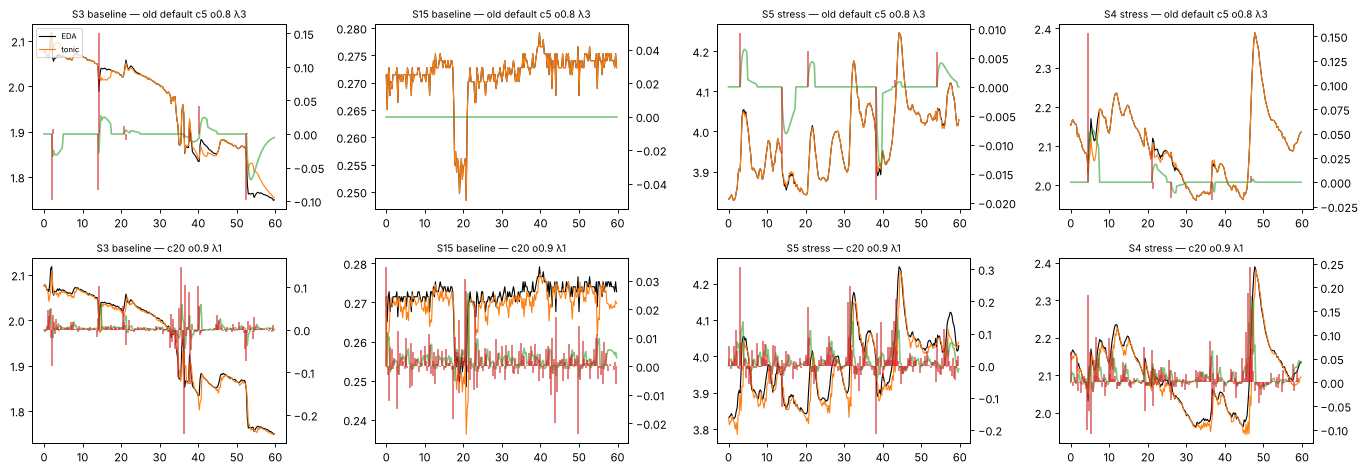

In [11]:
rng = np.random.default_rng(3)
idx = list(rng.choice(np.flatnonzero(y == 1), 2, replace=False)) + list(rng.choice(np.flatnonzero(y == 2), 2, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(17, 6))
t = np.arange(WIN) / FS
for col, i in enumerate(idx):
    for row, (ch, ov, ls, title) in enumerate([(5, 0.8, 3, "old default c5 o0.8 λ3"), (20, 0.9, 1, "c20 o0.9 λ1")]):
        D_, T_, P_ = gmsEDA_window(W[i], ch, ov, ls, 0)
        ax = axes[row, col]
        ax.plot(t, W[i], "k", lw=1, label="EDA"); ax.plot(t, T_, color="tab:orange", lw=1, label="tonic")
        ax2 = ax.twinx(); ax2.plot(t, P_, color="tab:green", alpha=.6, label="phasic")
        ax2.vlines(t, 0, D_, color="tab:red", alpha=.7, label="driver")
        ax.set_title(f"{meta.subject[i]} {'stress' if y[i] == 2 else 'baseline'} — {title}", fontsize=9)
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

### Which `gms` features drive the gain? (permutation importance, HistGB on `raw+gms`, all subjects)

In [12]:
from sklearn.inspection import permutation_importance
F = SETS[f"raw+gms [{BEST}]"]
m = SCREEN_MODELS["HistGB"]().fit(F.values, y)
imp = permutation_importance(m, F.values, y, n_repeats=5, random_state=0, n_jobs=-1)
pd.Series(imp.importances_mean, index=F.columns).sort_values(ascending=False).head(12).round(4)

gms_drv_neg_nnz      0.0301
p90                  0.0212
gms_drv_events       0.0211
min                  0.0201
gms_drv_bigevents    0.0198
skew                 0.0122
max                  0.0086
bp_0.5_2.0           0.0085
gms_rel_ton_slope    0.0082
p10                  0.0051
gms_ph_npeaks        0.0045
gms_ph_mean          0.0038
dtype: float64

## 6. Side check: does the tuned decomposition also help *with* per-subject normalisation?
The `raw` features here are robust-normalised per subject: `(x - median) / (p95 - p5)` over the whole recording, with no labels used. With them alone, HistGB reaches 0.935. The tuned `gms` features
are added unchanged: their counts and ratios are scale-free, and the rest are in µS.

In [13]:
RAWN = build_feature_table(W, meta, subject_scale(load_subjects(), "robust")).filter(like="raw_")
resN, pN = compare_feature_sets({"raw (robust-normalised)": RAWN,
                                 f"raw (robust) + gms [{BEST}]": pd.concat([RAWN, GF[BEST]], axis=1)},
                                y, groups, baseline="raw (robust-normalised)")
accN = resN.pivot(index="features", columns="model", values="acc"); accN["mean"] = accN.mean(axis=1)
display(accN.round(3))
pN.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw (robust) + gms [c20_o0.9_l1_nn0],0.925,0.888,0.875,0.888,0.894
raw (robust-normalised),0.935,0.876,0.885,0.884,0.895


,features,model,delta,wins,losses,p
0,raw (robust) + gms [c20_o0.9_l1_nn0],LogReg,0.012,6,5,0.477
1,raw (robust) + gms [c20_o0.9_l1_nn0],SVM-RBF,0.004,7,5,0.754
2,raw (robust) + gms [c20_o0.9_l1_nn0],RandomForest,-0.010,3,5,0.575
3,raw (robust) + gms [c20_o0.9_l1_nn0],HistGB,-0.009,5,5,0.508


## Conclusion

**Without per-subject normalisation, a tuned `gmsEDA` decomposition does improve classification.**

| features (µS, no normalisation) | LogReg | SVM | RF | HistGB | mean |
|---|---|---|---|---|---|
| raw (33) | 0.831 | 0.853 | 0.824 | 0.840 | 0.837 |
| raw + running-median control | 0.828 | 0.864 | 0.842 | 0.830 | 0.841 |
| raw + gmsEDA, old defaults (5 chops, 0.8, λ 3) | 0.840 | 0.847 | 0.816 | 0.840 | 0.836 |
| **raw + gmsEDA, 20 chops, overlap 0.9, λ 1** | **0.869** | **0.895** | **0.868** | **0.870** | **0.875** |

* **Size and consistency of the gain.** About +3 to +4 accuracy points for every classifier. 10–12 of 15 subjects improve, and the paired
  Wilcoxon p is 0.002–0.02 for LogReg, SVM and RF (0.10 for HistGB). The gain holds against the stronger
  `raw+rel` control (+2.9 to +4.1, p ≤ 0.026 for all four classifiers). The naive median decomposition gives
  nothing (+0.004), so the gain comes from `gmsEDA`, not from "any tonic/phasic split". The 28 `gmsEDA` features *alone*
  (0.871) already beat the 33 raw features.
* **Selection bias accounted for.** With the configuration chosen inside each LOSO fold from all 112 candidates (and
  "no decomposition"), HistGB reaches **0.885** (+4.6 over raw). LogReg gains only +1.0, because the inner
  selection with LogReg is noisy and sometimes picks configurations outside the good region.
* **Parameters.** The old defaults do *not* help. What matters is `lam_scale ≈ 1` together with many chops (short
  segments of 6–12 samples, i.e. 1.5–3 s) and high overlap (0.8–0.95). `force_nn=1` is slightly worse.
* **What the features capture.** The most useful `gms` features are the number of negative driver entries and the number of
  (large) driver events. With short segments and λ ≈ 1 the decomposition works as a detector of fast rises and
  falls in the EDA. These counts do not depend on the subject's absolute conductance level, which is presumably why
  they help most when no normalisation is applied. Negative driver values have no direct SCR interpretation, so this
  should be described as an *event/fluctuation representation* rather than a physiological SCR decomposition.
* **With per-subject normalisation** (section 6) the same features add nothing (0.894 vs 0.895 mean; HistGB 0.925
  vs 0.935). The normalised raw features already contain that information. The best overall result therefore
  remains 0.935 with normalisation. Without normalisation, `gmsEDA` raises accuracy from ~0.84 to 0.87–0.89.